二维高斯函数滤波核VS OpenCV库滤波核

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#有一部分代码搬运自滤波算法演示的代码
# 设置matplotlib显示中文(字体已改)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False


# 读取图像
img = cv2.imread('dandc.jpg')

# 检查图像是否成功读取
if img is None:
    print("错误：？！图图？！无法读取图像文件 'dandc.jpg'，请确保文件存在于当前目录")
else:
    print(f"图像读取成功！")
    print(f"图像尺寸: {img.shape}")
    print(f"图像类型: {img.dtype}")
    
    # 将BGR转换为RGB（matplotlib显示需要）
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    




#手动生成高斯滤波核
def gaosi(size , sigma):
    X = np.arange(-(size//2),(size//2)+1)
    xx , yy =np.meshgrid(X,X)
#权重
    k=np.exp(-(xx**2 + yy**2)/(2*sigma**2))
    k=k/np.sum(k)
    return k


# 手动生成高斯核
manual_kernel1 = gaosi(3, 1)
manual_kernel2= gaosi(5, 1)
manual_kernel3= gaosi(7, 2)

# OpenCV生成高斯核
opencv_kernel_1d1 = cv2.getGaussianKernel(3, 1)
opencv_kernel_1d2 = cv2.getGaussianKernel(5, 1)
opencv_kernel_1d3 = cv2.getGaussianKernel(7, 1)

# 将一维高斯核转换为二维
opencv_kernel1 = opencv_kernel_1d1 @ opencv_kernel_1d1.T
opencv_kernel2 = opencv_kernel_1d2 @ opencv_kernel_1d2.T
opencv_kernel3 = opencv_kernel_1d3 @ opencv_kernel_1d3.T

print("手动生成的高斯核：")
print("————第一个————,size=3,sigma=1")
print(manual_kernel1)
print("————第二个————,size=5,sigma=1")
print(manual_kernel2)
print("————第三个————,size=7,sigma=2")
print(manual_kernel3)
print("opencv生成的高斯核:")
print("————第一个————,size=3,sigma=1")
print(opencv_kernel1)
print("————第二个————,size=5,sigma=1")
print(opencv_kernel2)
print("————第三个————,size=7,sigma=2")
print(opencv_kernel3)
print("两者最大相对误差：")
print(np.max(np.abs(manual_kernel1 - opencv_kernel1)))
print(np.max(np.abs(manual_kernel2 - opencv_kernel2)))
print(np.max(np.abs(manual_kernel3 - opencv_kernel3)))

图像读取成功！
图像尺寸: (1444, 1090, 3)
图像类型: uint8
手动生成的高斯核：
————第一个————,size=3,sigma=1
[[0.07511361 0.1238414  0.07511361]
 [0.1238414  0.20417996 0.1238414 ]
 [0.07511361 0.1238414  0.07511361]]
————第二个————,size=5,sigma=1
[[0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.02193823 0.09832033 0.16210282 0.09832033 0.02193823]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]]
————第三个————,size=7,sigma=2
[[0.00492233 0.00919613 0.01338028 0.01516185 0.01338028 0.00919613
  0.00492233]
 [0.00919613 0.01718062 0.02499766 0.02832606 0.02499766 0.01718062
  0.00919613]
 [0.01338028 0.02499766 0.03637138 0.04121417 0.03637138 0.02499766
  0.01338028]
 [0.01516185 0.02832606 0.04121417 0.04670178 0.04121417 0.02832606
  0.01516185]
 [0.01338028 0.02499766 0.03637138 0.04121417 0.03637138 0.02499766
  0.01338028]
 [0.00919613 0.01718062 0.02499766 0.02832606 0.02499766 

手搓滤波对比结果+两种边界padding；第一种：zero padding

findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the following families were found: Noto Sans CJK SC
findfont: Generic family 'sans-serif' not found because none of the foll

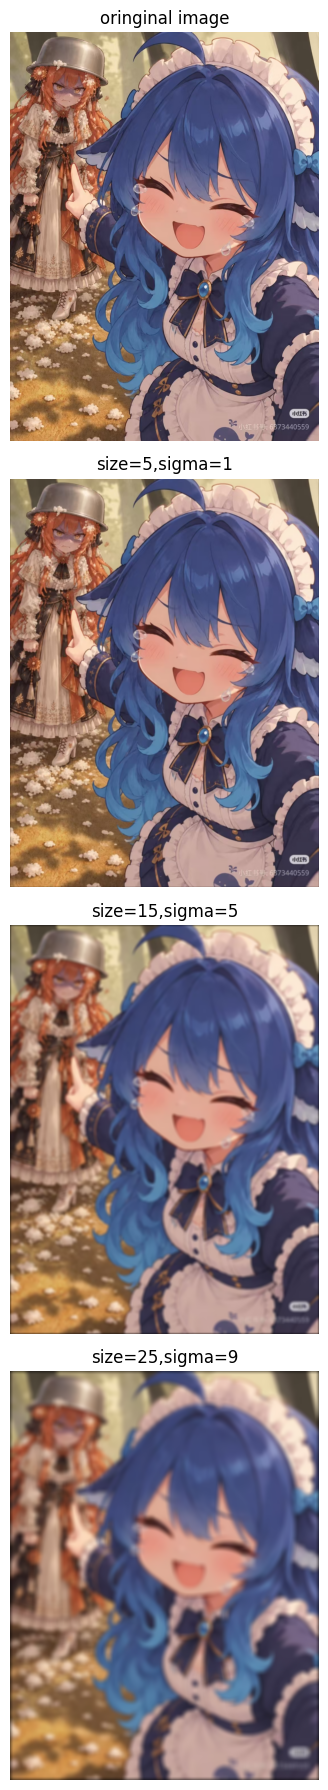

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#上文高斯滤波算法：
#手动生成高斯滤波核
def gaosi(size , sigma):
    X = np.arange(-(size//2),(size//2)+1)
    xx , yy =np.meshgrid(X,X)

    #权重
    k=np.exp(-(xx**2 + yy**2)/(2*sigma**2))
    k=k/np.sum(k)
    return k

k_small= gaosi(5,1)
k_middle= gaosi(15,5)
k_large= gaosi(25,9)












#——————————————手动二维卷积————————————————zero_padding————————

def zero_padding(img, pad):

    if img.ndim == 2:
        return np.pad(img, ((pad, pad), (pad, pad)), mode='constant', constant_values=0)

    else:
        return np.pad(img,  ((pad, pad), (pad, pad), (0, 0))  ,mode='constant', constant_values=0) 



def gaussian_filter_manual(img, kernel):

    # 核大小
    k_size = kernel.shape[0]

    # 填充宽度
    pad = k_size // 2

    # 边界
    img_pad = zero_padding(img, pad)
    img_pad = img_pad.astype(np.float64)

    # 图像尺寸
    h, w = img.shape[:2]

    # 判断图像类型
    if img.ndim == 2:

        result = np.zeros((h, w))

        for i in range(h):
            for j in range(w):

                # 当前区域
                region = img_pad[i:i+k_size, j:j+k_size]

                # 卷积
                result[i, j] = np.sum(region * kernel)

    else:

        c = img.shape[2]
        result = np.zeros((h, w, c))

        for i in range(h):
            for j in range(w):
                for ch in range(c):
                    region = img_pad[ i:i+k_size, j:j+k_size, ch]
                    result[i, j, ch] = np.sum(region * kernel)

    return np.clip(result, 0, 255).astype(np.uint8)



# 读取图片
img = cv2.imread('dandc.jpg')

if img is None:
    raise FileNotFoundError("没有找到 dandc.jpg")

# 转换为 RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)



#不同大小的滤波核匹配
manual_result1 = gaussian_filter_manual(img_rgb, k_small)
manual_result2 = gaussian_filter_manual(img_rgb, k_middle)
manual_result3 = gaussian_filter_manual(img_rgb, k_large)
results=[manual_result1,manual_result2,manual_result3 ]

# 展示结果(字体卡bug了识别不了，全写的英文)
fig, axes = plt.subplots(4, 1, figsize=(8, 18))

axes[0].imshow(img_rgb)
axes[0].set_title('oringinal image')
axes[0].axis('off')

axes[0].axis('off')

for i in range(0,3):

    axes[i+1].imshow(results[i])
    axes[i+1].set_title(f"size={i*10+5},sigma={4*i+1},zero padding")
    axes[i+1].axis('off')


plt.tight_layout()
plt.show()


第二种padding：copy padding（第一种zero padding在上文已实现）

(np.float64(-0.5), np.float64(1089.5), np.float64(1443.5), np.float64(-0.5))

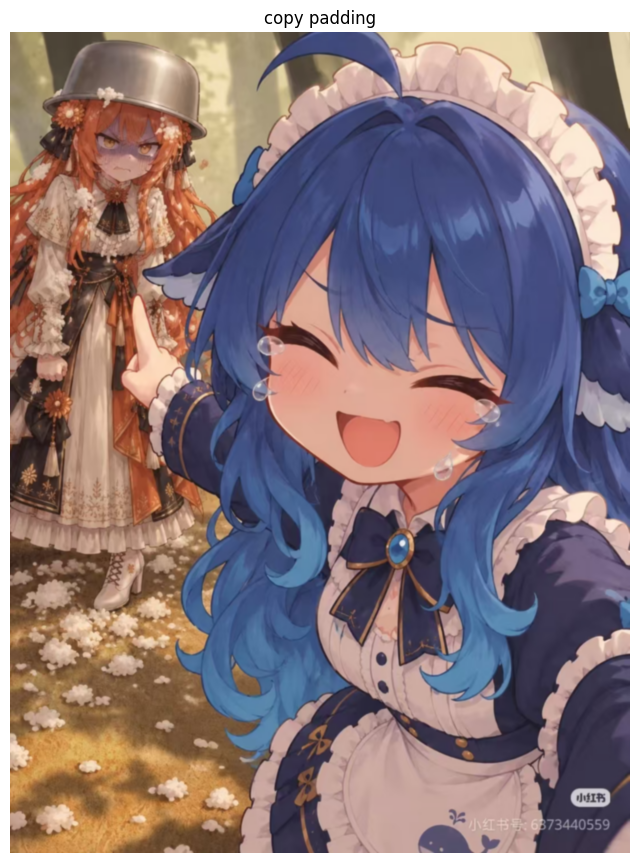

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#上文高斯滤波算法：
#手动生成高斯滤波核
def gaosi(size , sigma):
    X = np.arange(-(size//2),(size//2)+1)
    xx , yy =np.meshgrid(X,X)

    #权重
    k=np.exp(-(xx**2 + yy**2)/(2*sigma**2))
    k=k/np.sum(k)
    return k

k_small= gaosi(5,1)

def copy_padding(img, pad):

    h, w = img.shape[:2]

    # 创建新矩阵
    result = np.zeros( (h + 2 * pad, w + 2 * pad, img.shape[2]), dtype=img.dtype)

    # 复制原始图像
    result[pad:pad+h, pad:pad+w] = img

    # 复制上下边界
    for i in range(pad):
        result[i, pad:pad+w] = img[0, :]
        result[pad+h+i, pad:pad+w] = img[-1, :]

    # 复制左右边界
    for j in range(pad):
        result[:, j] = result[:, pad]
        result[:, pad+w+j] = result[:, pad+w-1]

    return result



def gaussian_filter_manual(img, kernel):

    # 核大小
    k_size = kernel.shape[0]

    # 填充宽度
    pad = k_size // 2

    # 边界
    img_pad = copy_padding(img, pad)
    img_pad = img_pad.astype(np.float64)

    # 图像尺寸
    h, w = img.shape[:2]

    # 判断图像类型
    if img.ndim == 2:

        result = np.zeros((h, w))

        for i in range(h):
            for j in range(w):

                # 当前区域
                region = img_pad[i:i+k_size, j:j+k_size]

                # 卷积
                result[i, j] = np.sum(region * kernel)

    else:

        c = img.shape[2]
        result = np.zeros((h, w, c))

        for i in range(h):
            for j in range(w):
                for ch in range(c):
                    region = img_pad[ i:i+k_size, j:j+k_size, ch]
                    result[i, j, ch] = np.sum(region * kernel)

    return np.clip(result, 0, 255).astype(np.uint8)



# 读取图片
img = cv2.imread('dandc.jpg')

if img is None:
    raise FileNotFoundError("没有找到 dandc.jpg")

# 转换为 RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 1, figsize=(8, 16))
manual_result4 = gaussian_filter_manual(img_rgb, k_small)
axes.imshow(manual_result4)
axes.set_title('copy padding')
axes.axis('off')

